# Croydon spatial inference and grid sensitivity

**Status:** the saved results include the area summary and revised map, with no saved errors; the export helper retained the report PNG unchanged. See the [saved execution evidence](../docs/methods-and-validation.md#saved-execution-and-figure-evidence) for the current metadata gap and the limits of fresh-kernel verification.

Run from `notebooks/` with the project environment and supplied inputs; no earlier notebook kernel is needed. Figure export is enabled with identical PNGs retained and changed PNGs replaced after a complete save. The report map uses a new filename, leaving the original inference PNG untouched; the exported layout has been visually inspected, while final PDF layout and complete attribution remain pending.

## Task 5: Local concentration inference and sensitivity

### 5.1 Design and interpretation

Analyse qualifying 2022–2025 collisions inside Croydon's fixed December 2024 footprint. Use a 500 m main grid and 250 m sensitivity grid, both anchored at British National Grid (0, 0), retaining all positive-area clips and zeros.

Each test sums counts in cells whose full-square centres are within 850 m of the focal cell, including itself. Before clipping, this covers nine cells (2.25 km²) at 500 m and 37 (2.3125 km²) at 250 m; the fixed exploratory distance gives slightly different stepped windows.

Under the null, N events are independently uniform over the footprint: a neighbourhood with clipped area share a has count S ~ Binomial(N, a). Calculate P(S ≥ observed) directly, then apply Benjamini–Yekutieli (BY) correction at a 5% false discovery rate across all cells separately per grid: [R20](../docs/references.md#r20), [R21](../docs/references.md#r21). This area-based neighbourhood count test is not standard Gi*; the sensitivity map is robustness evidence, not a second jointly controlled discovery set.

### 5.2 Inputs, provenance and environment

**Purpose:** verify input presence and hashes against the manifest and saved validation run, then record package versions and settings.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import NamedTemporaryFile
from importlib.metadata import version
import hashlib
import json
import os
import math
from numbers import Integral

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import CRS
from shapely import box
from IPython.display import display

DATA_DIR = Path(os.environ.get("COMP1890_DATA_DIR", "../data")).expanduser()
VALIDATION_DIR = Path(os.environ.get(
    "COMP1890_VALIDATION_DIR", str(DATA_DIR / "derived/spatial_validation_closure")
)).expanduser()
BOUNDARY_PATH = Path(os.environ.get(
    "COMP1890_BOUNDARY_PATH", str(DATA_DIR / "ons-lad-december-2024-uk-bfe.gpkg")
)).expanduser()
INPUTS = {
    "boundary": BOUNDARY_PATH,
    "guide": DATA_DIR / "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx",
    "candidates": DATA_DIR / "derived/pedestrian_collision_candidates.csv",
    "audit": VALIDATION_DIR / "collision_validation_audit.csv",
    "borough_evidence": VALIDATION_DIR / "borough_selection_evidence.csv",
    "validation_run": VALIDATION_DIR / "validation_run.json",
    "manifest": DATA_DIR / "download-manifest.json",
}
STUDY_CODE, STUDY_NAME = "E09000008", "Croydon"
YEARS = (2022, 2023, 2024, 2025)
EXPECTED_ANNUAL = {2022: 190, 2023: 200, 2024: 180, 2025: 222}
GRID_CRS = "EPSG:27700"
BOUNDARY_LAYER = "LAD_DEC_24_UK_BFE"
GRID_SIZES_M = (500, 250)
MAIN_SIZE_M, SENSITIVITY_SIZE_M = GRID_SIZES_M
RADIUS_M = 850.0
FDR_LEVEL = 0.05
EXPECTED_CELLS = {500: 415, 250: 1520}
GRID_ORIGIN_M = (0.0, 0.0)  # One British National Grid lattice origin for every size.
MAX_CANDIDATE_CELLS = 50000
# Image exports are optional; analysis inputs and dataset exports remain unchanged.
EXPORT_FIGURES = True
FIGURE_DIR = Path(os.environ.get("COMP1890_FIGURE_DIR", "../evidence")).expanduser()


def save_report_figure(figure, filename):
    """Skip identical PNGs and replace changed images only after a complete save."""
    if not EXPORT_FIGURES:
        return
    output_path = FIGURE_DIR / filename
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=300, bbox_inches="tight")
        png_bytes = buffer.getvalue()
    existed = output_path.exists()
    if existed and output_path.read_bytes() == png_bytes:
        print(f"Figure unchanged; kept existing PNG: {output_path}")
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    temporary_path = None
    try:
        # A closed temporary file in the same directory supports atomic replacement.
        with NamedTemporaryFile(mode="wb", dir=FIGURE_DIR,
                                prefix=f".{output_path.name}.", suffix=".tmp",
                                delete=False) as handle:
            temporary_path = Path(handle.name)
            handle.write(png_bytes)
        os.replace(temporary_path, output_path)
    finally:
        if temporary_path is not None:
            temporary_path.unlink(missing_ok=True)
    action = "Updated" if existed else "Saved"
    print(f"{action} figure: {output_path}")

for path in INPUTS.values():
    if not path.is_file():
        raise FileNotFoundError(f"Required input missing: {path}. Check DATA_DIR and VALIDATION_DIR.")
manifest = json.loads(INPUTS["manifest"].read_text(encoding="utf-8"))
validation_run = json.loads(INPUTS["validation_run"].read_text(encoding="utf-8"))
if not isinstance(validation_run, dict) or not isinstance(validation_run.get("input_sha256"), dict):
    raise ValueError("Validation run metadata lacks input hashes; inspect notebook 02's export.")
entries = {entry["file"]: entry for entry in manifest["files"]}
input_hashes = {}
for label, path in INPUTS.items():
    with path.open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    input_hashes[label] = digest
    if label in ("boundary", "guide", "candidates"):
        if validation_run["input_sha256"].get(label) != digest:
            raise ValueError(f"Input differs from the saved validation run: {label}.")
    if label in ("boundary", "guide"):
        entry = entries.get(path.name)
        if entry is None or entry["bytes"] != path.stat().st_size or entry["sha256"] != digest:
            raise ValueError(f"Original input differs from its manifest: {path.name}.")
versions = {name: version(name) for name in (
    "pandas", "numpy", "geopandas", "shapely", "pyproj", "pyogrio", "matplotlib")}
inference_context = {
    "study_code": STUDY_CODE, "period": list(YEARS), "reference_geography": "December 2024 footprint",
    "input_sha256": input_hashes, "versions": versions, "grid_origin_m": GRID_ORIGIN_M,
    "grid_sizes_m": GRID_SIZES_M, "method": "area-based neighbourhood binomial upper tail with BY",
    "radius_m": RADIUS_M, "fdr_level": FDR_LEVEL, "families": "separate per grid", "exports": "none",
}
display(pd.Series(versions, name="installed_version"))
display(pd.Series(input_hashes, name="sha256"))
print("Approved scope:", STUDY_NAME, YEARS, "within the December 2024 footprint.")
print("Hashes identify inputs; they do not verify artifact contents or positional accuracy.")


pandas         3.1.1
numpy          2.5.4
geopandas      1.2.0
shapely        2.2.0
pyproj         3.8.0
pyogrio       0.13.0
matplotlib    3.11.2
Name: installed_version, dtype: str

boundary            a421a026170391ade115e7424b8c4e06e682e0290978b8...
guide               51b08606ef3dad1ae5d4c8726241b022fc8e4bbdc910ef...
candidates          6599e3a378f930db908b225c5b554c624ee94159a5f419...
audit               0da6449bab739d5f3c970e95e819164cb716ca47559288...
borough_evidence    5ad9c445742f8b9309657f1592a9d9ad53c0380e01bfe0...
validation_run      d9966c7fc8f13000d54db2e79732e0ec31308ca31ef280...
manifest            444baba3f58e973b172059a75e48326f46cb4e5cf2e315...
Name: sha256, dtype: str

Approved scope: Croydon (2022, 2023, 2024, 2025) within the December 2024 footprint.
Hashes identify inputs; they do not verify artifact contents or positional accuracy.


**Findings:** boundary, guide and candidate hashes match the saved validation run; the originals also pass boundary/guide manifest checks. Hash agreement identifies inputs but does not independently validate derived artifacts.

### 5.3 Reproduce the fixed-footprint selection

**Purpose:** reconcile audit fields with candidates, check selected points against the original Croydon polygon and reproduce the saved annual baseline. Preserve original district-code differences.

In [2]:
source_fields = ["collision_index", "source_file_year", "collision_year", "date",
                 "location_easting_osgr", "location_northing_osgr", "local_authority_ons_district"]
audit = pd.read_csv(INPUTS["audit"], dtype=str, keep_default_na=False, encoding="utf-8-sig")
required = set(source_fields) | {"membership_status", "geometric_london_code"}
if not required.issubset(audit.columns):
    raise ValueError("Validation audit lacks required fields; inspect notebook 02's export.")
candidates = pd.read_csv(INPUTS["candidates"], usecols=source_fields,
                         dtype=str, keep_default_na=False, encoding="utf-8-sig")
for label, frame in (("audit", audit), ("candidates", candidates)):
    if frame["collision_index"].str.strip().eq("").any() or not frame["collision_index"].is_unique:
        raise ValueError(f"{label} requires nonblank, unique collision IDs.")
left = audit[source_fields].set_index("collision_index").sort_index()
right = candidates[source_fields].set_index("collision_index").sort_index()
if not left.equals(right):
    raise ValueError("Audit source fields do not reconcile with the candidate input.")
if not audit["source_file_year"].eq(audit["collision_year"]).all():
    raise ValueError("Audit source years and collision years differ.")
footprint_frame = gpd.read_file(INPUTS["boundary"], layer=BOUNDARY_LAYER,
    where=f"LAD24CD = '{STUDY_CODE}'", engine="pyogrio")
if (len(footprint_frame) != 1 or footprint_frame.crs != CRS.from_user_input(GRID_CRS)
        or footprint_frame.iloc[0]["LAD24NM"] != STUDY_NAME):
    raise ValueError("Expected one Croydon reference polygon in EPSG:27700.")
footprint = footprint_frame.geometry.iloc[0]
if (footprint is None or footprint.is_empty or not footprint.is_valid
        or footprint.geom_type not in ("Polygon", "MultiPolygon")):
    raise ValueError("The reference footprint must be a valid nonempty polygon; no repair applied.")
year_mask = audit["source_file_year"].isin([str(year) for year in YEARS])
recorded_here = year_mask & audit["local_authority_ons_district"].eq(STUDY_CODE)
if (recorded_here & audit["membership_status"].ne("unique_interior")).any():
    raise ValueError("Recorded-Croydon cases with unresolved membership require review.")
selected_mask = (year_mask & audit["membership_status"].eq("unique_interior")
                 & audit["geometric_london_code"].eq(STUDY_CODE))
study_records = audit.loc[selected_mask].copy()
if study_records.empty:
    raise ValueError("No collisions satisfy the approved footprint and period.")
study_records["easting"] = pd.to_numeric(study_records["location_easting_osgr"], errors="raise")
study_records["northing"] = pd.to_numeric(study_records["location_northing_osgr"], errors="raise")
if not np.isfinite(study_records[["easting", "northing"]].to_numpy(dtype=float)).all():
    raise ValueError("Selected grid coordinates must be finite.")
study_records["study_year"] = pd.to_numeric(study_records["source_file_year"], errors="raise").astype(int)
study_dates = pd.to_datetime(study_records["date"], format="%d/%m/%Y", errors="raise")
if not study_dates.dt.year.eq(study_records["study_year"]).all():
    raise ValueError("Selected dates disagree with their source years.")
study_points = gpd.GeoDataFrame(study_records.copy(),
    geometry=gpd.points_from_xy(study_records["easting"], study_records["northing"]), crs=GRID_CRS)
if not study_points.within(footprint).all():
    raise ValueError("Selected points do not all lie inside the reference footprint; inspect the audit.")
annual_counts = study_records.groupby("study_year").size().reindex(YEARS, fill_value=0)
if annual_counts.to_dict() != EXPECTED_ANNUAL:
    raise ValueError("Selected annual totals differ from the saved baseline; investigate before aggregation.")
borough_evidence = pd.read_csv(INPUTS["borough_evidence"], dtype=str, keep_default_na=False)
reference_row = borough_evidence.loc[borough_evidence["LAD24CD"].eq(STUDY_CODE)]
if len(reference_row) != 1 or int(reference_row.iloc[0]["geometric_total"]) != len(study_records):
    raise ValueError("Selected total does not reconcile with the borough evidence export.")
for year in YEARS:
    if int(reference_row.iloc[0][str(year)]) != int(annual_counts.loc[year]):
        raise ValueError("Annual totals do not reconcile with the borough evidence export.")
display(pd.Series({"selected_collisions": len(study_records),
    "unique_collision_ids": study_records["collision_index"].nunique(),
    "all_inside_reference_footprint": bool(study_points.within(footprint).all())}))
display(study_records[["collision_index", "source_file_year", "local_authority_ons_district",
                       "geometric_london_code", "membership_status"]].head())


selected_collisions                792
unique_collision_ids               792
all_inside_reference_footprint    True
dtype: object

,collision_index,source_file_year,local_authority_ons_district,geometric_london_code,membership_status
15,2022010352897,2022,E09000008,E09000008,unique_interior
17,2022010352922,2022,E09000008,E09000008,unique_interior
56,2022010353567,2022,E09000008,E09000008,unique_interior
110,2022010354330,2022,E09000008,E09000008,unique_interior
114,2022010354371,2022,E09000008,E09000008,unique_interior


**Findings:** 792 unique collisions lie inside the footprint, with annual counts of 190 / 200 / 180 / 222 for 2022–2025. Source fields and totals reconcile with the saved evidence; original district codes remain unchanged.

### 5.4 Grid and inference functions

**Purpose:** define grid assignment, neighbourhoods, binomial tails, BY correction and area comparison. Decisions use log probabilities; displayed probabilities have a labelled numerical floor.

In [ ]:
def build_count_grid(study_points, footprint, size_m, origin=(0.0, 0.0), max_cells=50000):
    """Count unique interior events on a half-open lattice; retain positive-area clips."""
    if not np.isfinite(size_m) or size_m <= 0:
        raise ValueError("Grid size must be finite and positive.")
    if len(origin) != 2 or not np.isfinite(origin).all():
        raise ValueError("Grid origin requires two finite coordinates.")
    if (footprint.is_empty or not footprint.is_valid
            or footprint.geom_type not in ("Polygon", "MultiPolygon")):
        raise ValueError("A valid nonempty polygon footprint is required.")
    if study_points.crs != CRS.from_user_input("EPSG:27700"):
        raise ValueError("Grid counting requires points in EPSG:27700.")
    if (study_points["collision_index"].isna().any()
            or study_points["collision_index"].astype(str).str.strip().eq("").any()
            or not study_points["collision_index"].is_unique):
        raise ValueError("Each collision must have a nonblank unique ID.")
    xy = np.column_stack((study_points.geometry.x, study_points.geometry.y))
    if not np.isfinite(xy).all() or not study_points.within(footprint).all():
        raise ValueError("Every event must be finite and strictly inside the footprint.")
    x0, y0 = origin
    xmin, ymin, xmax, ymax = footprint.bounds
    col_min, col_max = int(np.floor((xmin - x0) / size_m)), int(np.floor((xmax - x0) / size_m))
    row_min, row_max = int(np.floor((ymin - y0) / size_m)), int(np.floor((ymax - y0) / size_m))
    candidate_count = (col_max - col_min + 1) * (row_max - row_min + 1)
    if candidate_count > max_cells:
        raise ValueError(f"Grid needs {candidate_count:,} candidate cells; review size and max_cells before proceeding.")
    cols, rows = np.meshgrid(np.arange(col_min, col_max + 1), np.arange(row_min, row_max + 1))
    cols, rows = cols.ravel(), rows.ravel()
    x, y = x0 + cols * size_m, y0 + rows * size_m
    squares = gpd.GeoDataFrame({"grid_col": cols, "grid_row": rows},
        geometry=box(x, y, x + size_m, y + size_m), crs=study_points.crs)
    clipped = squares.geometry.intersection(footprint)
    positive_area = clipped.area.gt(0)
    grid = squares.loc[positive_area].copy()
    grid.geometry = clipped.loc[positive_area]
    if grid.empty or not grid.geometry.is_valid.all():
        raise ValueError("Clipped grid is empty or invalid; no automatic repair applied.")
    grid["area_m2"] = grid.geometry.area
    grid["area_fraction"] = grid["area_m2"] / float(size_m ** 2)
    # Dimensionless floating-point allowance for classifying full squares, not a spatial cutoff.
    fraction_tolerance = 1e-9
    if not grid["area_fraction"].between(0, 1 + fraction_tolerance, inclusive="right").all():
        raise ValueError("Cell area fractions are outside the expected range.")
    grid["partial_cell"] = grid["area_fraction"].lt(1 - fraction_tolerance)
    if not np.isclose(grid["area_m2"].sum(), footprint.area, rtol=1e-9, atol=1e-4):
        raise ValueError("Clipped cell areas do not reconcile with footprint area.")
    grid = grid.set_index(["grid_col", "grid_row"]).sort_index()
    assigned = pd.DataFrame({"collision_index": study_points["collision_index"].to_numpy(),
        "grid_col": np.floor((xy[:, 0] - x0) / size_m).astype(np.int64),
        "grid_row": np.floor((xy[:, 1] - y0) / size_m).astype(np.int64)})
    counts = assigned.groupby(["grid_col", "grid_row"]).size()
    if not counts.index.isin(grid.index).all():
        raise ValueError("An event was assigned to a cell without positive footprint area.")
    grid["collision_count"] = counts.reindex(grid.index, fill_value=0).astype(int)
    if grid["collision_count"].sum() != len(study_points):
        raise ValueError("Cell counts do not reconcile with selected collision totals.")
    grid = grid.reset_index()
    grid["cell_id"] = [f"{size_m:g}m_{col}_{row}" for col, row in zip(
        grid["grid_col"], grid["grid_row"], strict=True)]
    return grid, assigned


def summarise_grid(grid, size_m):
    """Describe all retained cells, with occupied-cell statistics explicitly labelled."""
    counts = grid["collision_count"]
    occupied = counts.loc[counts.gt(0)]
    partial = grid["partial_cell"]
    total = int(counts.sum())
    return {"cell_size_m": size_m, "retained_cells": len(grid),
        "zero_count_cells": int(counts.eq(0).sum()), "zero_count_pct": 100 * counts.eq(0).mean(),
        "occupied_cells": len(occupied), "mean_count_all_cells": counts.mean(),
        "median_count_all_cells": counts.median(), "p95_count_all_cells": counts.quantile(0.95),
        "median_count_occupied_cells": occupied.median() if len(occupied) else np.nan,
        "maximum_count": int(counts.max()), "partial_cells": int(partial.sum()),
        "partial_cell_pct": 100 * partial.mean(), "minimum_area_fraction": grid["area_fraction"].min(),
        "events_in_partial_cells": int(counts.loc[partial].sum()),
        "event_pct_in_partial_cells": 100 * counts.loc[partial].sum() / total if total else np.nan,
        "total_collisions": total}


In [4]:
def binomial_log_upper_tail(observed, total, probability):
    """Return log P[X >= observed] for Binomial(total, probability)."""
    if (not isinstance(total, Integral) or isinstance(total, bool) or total < 0
            or not isinstance(observed, Integral) or isinstance(observed, bool)
            or not 0 <= observed <= total):
        raise ValueError("Counts must be integers with 0 <= observed <= total.")
    if not math.isfinite(probability) or not 0 <= probability <= 1:
        raise ValueError("The binomial probability must be finite and within [0, 1].")
    if observed == 0 or probability == 1:
        return 0.0
    if probability == 0:
        return -math.inf
    # Direct discrete upper-tail sum, evaluated using log-sum-exp.
    # Scope is the selected event total, not an unbounded large-N algorithm.
    log_factorial = math.lgamma(total + 1)
    log_p, log_one_minus_p = math.log(probability), math.log1p(-probability)
    terms = [log_factorial - math.lgamma(k + 1) - math.lgamma(total - k + 1)
             + k * log_p + (total - k) * log_one_minus_p
             for k in range(observed, total + 1)]
    maximum = max(terms)
    return min(0.0, maximum + math.log(math.fsum(math.exp(t - maximum) for t in terms)))


def by_adjust_log(log_p_values):
    """BY adjusted p-values in log space, preserving original row order."""
    values = np.asarray(log_p_values, dtype=float)
    if values.ndim != 1 or values.size == 0 or np.isnan(values).any() or (values > 0).any():
        raise ValueError("Provide a nonempty one-dimensional array of log p-values <= 0.")
    count = values.size
    order = np.argsort(values, kind="stable")
    harmonic = math.fsum(1 / rank for rank in range(1, count + 1))
    ranked = values[order] + math.log(count * harmonic) - np.log(np.arange(1, count + 1))
    adjusted_sorted = np.minimum(0.0, np.minimum.accumulate(ranked[::-1])[::-1])
    adjusted = np.empty(count, dtype=float)
    adjusted[order] = adjusted_sorted
    return adjusted


def neighbourhood_membership(grid, size_m, radius_m):
    """Binary full-square centre distances; clipping never moves the centres."""
    if (not math.isfinite(size_m) or size_m <= 0
            or not math.isfinite(radius_m) or radius_m < 0):
        raise ValueError("Cell size must be positive and radius nonnegative, both finite.")
    if not {"grid_col", "grid_row"}.issubset(grid.columns) or grid.empty:
        raise ValueError("A nonempty grid with lattice row and column indices is required.")
    if len(grid) > 5000:
        raise ValueError("Review pairwise memory use before testing more than 5,000 cells.")
    lattice = grid[["grid_col", "grid_row"]].to_numpy(dtype=float)
    if (not np.isfinite(lattice).all() or not np.equal(lattice, np.floor(lattice)).all()
            or grid.duplicated(["grid_col", "grid_row"]).any()):
        raise ValueError("Lattice indices must be finite, integral and unique.")
    dx = (lattice[:, 0, None] - lattice[None, :, 0]) * size_m
    dy = (lattice[:, 1, None] - lattice[None, :, 1]) * size_m
    return np.hypot(dx, dy) <= radius_m


def local_count_test(grid, size_m, radius_m, footprint_area, fdr_level=0.05):
    """Test each neighbourhood under uniform independent event locations."""
    if not math.isfinite(fdr_level) or not 0 < fdr_level < 1:
        raise ValueError("FDR level must be between zero and one.")
    if not {"collision_count", "area_m2"}.issubset(grid.columns):
        raise ValueError("Grid counts and clipped areas are required.")
    counts = grid["collision_count"].to_numpy(dtype=float)
    areas = grid["area_m2"].to_numpy(dtype=float)
    if (not np.isfinite(counts).all() or (counts < 0).any()
            or not np.equal(counts, np.floor(counts)).all()):
        raise ValueError("Collision counts must be finite nonnegative integers.")
    if (not math.isfinite(footprint_area) or footprint_area <= 0
            or not np.isfinite(areas).all() or (areas <= 0).any()
            or (areas > size_m ** 2 * (1 + 1e-9)).any()
            or not np.isclose(math.fsum(areas), footprint_area, rtol=1e-9, atol=1e-4)):
        raise ValueError("Positive clipped cell areas must reconcile with the footprint.")
    total = int(math.fsum(counts))
    if total <= 0:
        raise ValueError("At least one selected collision is required for inference.")
    membership = neighbourhood_membership(grid, size_m, radius_m)
    observed = membership @ counts.astype(np.int64)
    neighbourhood_area = membership @ areas
    area_share = np.minimum(neighbourhood_area / footprint_area, 1.0)
    expected = total * area_share
    if (area_share <= 0).any():
        raise ValueError("Neighbourhood area shares must be positive.")
    log_p = np.array([binomial_log_upper_tail(int(value), total, float(share))
                      for value, share in zip(observed, area_share, strict=True)])
    log_adjusted = by_adjust_log(log_p)
    result = grid.copy(deep=True)
    result["neighbour_count_excluding_self"] = membership.sum(axis=1) - 1
    result["neighbourhood_area_m2"] = neighbourhood_area
    result["observed_neighbourhood_count"] = observed
    result["expected_neighbourhood_count"] = expected
    result["excess_neighbourhood_count"] = observed - expected
    result["observed_expected_ratio"] = observed / expected
    result["log_p_upper"] = log_p
    result["log_p_by"] = log_adjusted
    # These display columns are floored; all decisions use the unfloored logs.
    log_floor = math.log(np.finfo(float).tiny)
    result["p_upper_display_floor"] = np.exp(np.maximum(log_p, log_floor))
    result["p_by_display_floor"] = np.exp(np.maximum(log_adjusted, log_floor))
    result["by_significant"] = log_adjusted <= math.log(fdr_level)
    return result


def summarise_inference(result, size_m):
    """Summarise focal-cell footprints; overlapping neighbourhood sums are not added."""
    flagged = result["by_significant"]
    return {"cell_size_m": size_m, "tested_cells": len(result),
            "selected_collisions": int(result["collision_count"].sum()),
            "flagged_focal_cells": int(flagged.sum()),
            "flagged_focal_area_km2": result.loc[flagged, "area_m2"].sum() / 1e6,
            "events_in_flagged_focal_cells": int(result.loc[flagged, "collision_count"].sum()),
            "minimum_neighbours": int(result["neighbour_count_excluding_self"].min()),
            "maximum_neighbours": int(result["neighbour_count_excluding_self"].max()),
            "self_only_windows": int(result["neighbour_count_excluding_self"].eq(0).sum())}


def compare_flagged_areas(main_result, sensitivity_result):
    """Compare unions of flagged clipped focal cells, not their test windows."""
    if main_result.crs != sensitivity_result.crs or main_result.crs != CRS.from_epsg(27700):
        raise ValueError("Area comparison requires both grids in EPSG:27700.")
    main_area = main_result.loc[main_result["by_significant"]].geometry.union_all()
    alternative_area = sensitivity_result.loc[sensitivity_result["by_significant"]].geometry.union_all()
    overlap = main_area.intersection(alternative_area).area
    union = main_area.union(alternative_area).area
    return {"overlap_km2": overlap / 1e6, "union_km2": union / 1e6,
            "intersection_over_union": overlap / union if union > 0 else np.nan,
            "share_main_flagged_area_reproduced": overlap / main_area.area if main_area.area > 0 else np.nan}


**Findings:** the functions check counts, clipped areas, lattice indices and probability inputs. BY correction includes every retained cell; these safeguards do not validate the spatial null.

### 5.5 Main analysis: 500 m grid

**Purpose:** reproduce the saved 415-cell grid and test each neighbourhood. Display effect sizes and the 20 smallest adjusted p-values while retaining the complete correction family.

In [5]:
main_grid, main_assignments = build_count_grid(study_points, footprint, MAIN_SIZE_M, origin=GRID_ORIGIN_M)
if len(main_grid) != EXPECTED_CELLS[MAIN_SIZE_M]:
    raise ValueError("Main-grid cell total differs from notebook 03's saved baseline.")
main_result = local_count_test(main_grid, MAIN_SIZE_M, RADIUS_M, footprint.area, FDR_LEVEL)
RESULT_COLUMNS = ["cell_id", "collision_count", "partial_cell", "neighbour_count_excluding_self",
                  "neighbourhood_area_m2", "observed_neighbourhood_count", "expected_neighbourhood_count",
                  "excess_neighbourhood_count", "observed_expected_ratio", "log_p_upper", "log_p_by",
                  "p_upper_display_floor", "p_by_display_floor", "by_significant"]
display(pd.Series(summarise_inference(main_result, MAIN_SIZE_M)))
display(main_result.sort_values("log_p_by")[RESULT_COLUMNS].head(20))
print("Probability display floor:", np.finfo(float).tiny, "; significance uses unfloored log probabilities.")


cell_size_m                      500.00000
tested_cells                     415.00000
selected_collisions              792.00000
flagged_focal_cells               74.00000
flagged_focal_area_km2            17.39247
events_in_flagged_focal_cells    495.00000
minimum_neighbours                 2.00000
maximum_neighbours                 8.00000
self_only_windows                  0.00000
dtype: float64

,cell_id,collision_count,partial_cell,neighbour_count_excluding_self,neighbourhood_area_m2,observed_neighbourhood_count,expected_neighbourhood_count,excess_neighbourhood_count,observed_expected_ratio,log_p_upper,log_p_by,p_upper_display_floor,p_by_display_floor,by_significant
170,500m_1064_332,28,False,8,2250000.0,110,20.60923,89.39077,5.337414,-103.239003,-95.322641,1.458380e-45,3.998556e-42,True
199,500m_1065_331,26,False,8,2250000.0,109,20.60923,88.39077,5.288892,-101.440497,-94.217281,8.809517e-45,1.207688e-41,True
169,500m_1064_331,9,False,8,2250000.0,105,20.60923,84.39077,5.094805,-94.352821,-87.535070,1.054607e-41,9.638333e-39,True
200,500m_1065_332,6,False,8,2250000.0,101,20.60923,80.39077,4.900717,-87.439350,-80.909282,1.060652e-38,7.270183e-36,True
171,500m_1064_333,9,False,8,2250000.0,93,20.60923,72.39077,4.512541,-74.158463,-67.851539,6.214249e-33,3.407620e-30,True
140,500m_1063_332,7,False,8,2250000.0,91,20.60923,70.39077,4.415497,-70.956677,-64.832074,1.527237e-31,6.978915e-29,True
141,500m_1063_333,18,False,8,2250000.0,89,20.60923,68.39077,4.318453,-67.804006,-61.833553,3.573505e-30,1.399681e-27,True
139,500m_1063_331,4,False,8,2250000.0,81,20.60923,60.39077,3.930278,-55.703857,-49.866936,6.428686e-25,2.203255e-22,True
173,500m_1064_335,1,False,8,2250000.0,80,20.60923,59.39077,3.881756,-54.250926,-48.531788,2.748667e-24,8.373601e-22,True
111,500m_1062_334,6,False,8,2250000.0,79,20.60923,58.39077,3.833234,-52.811702,-47.380246,1.159229e-23,2.648625e-21,True


Probability display floor: 2.2250738585072014e-308 ; significance uses unfloored log probabilities.


**Findings:** 74 of 415 focal cells pass BY correction, covering 17.39 km² and containing 495 collisions (62.5%). The lowest-adjusted-p neighbourhood has 110 collisions versus 20.61 expected, a ratio of 5.34. Significance applies to the neighbourhood, not the focal cell alone.

### 5.6 Sensitivity analysis: 250 m grid

**Purpose:** repeat at 250 m using the same events, origin, 850 m distance rule, null and correction method. Reproduce 1,520 cells and correct this family separately.

In [6]:
sensitivity_grid, sensitivity_assignments = build_count_grid(
    study_points, footprint, SENSITIVITY_SIZE_M, origin=GRID_ORIGIN_M)
if len(sensitivity_grid) != EXPECTED_CELLS[SENSITIVITY_SIZE_M]:
    raise ValueError("Sensitivity-grid cell total differs from notebook 03's saved baseline.")
if set(main_assignments["collision_index"]) != set(sensitivity_assignments["collision_index"]):
    raise ValueError("Main and sensitivity grids do not contain identical collision IDs.")
sensitivity_result = local_count_test(
    sensitivity_grid, SENSITIVITY_SIZE_M, RADIUS_M, footprint.area, FDR_LEVEL)
display(pd.Series(summarise_inference(sensitivity_result, SENSITIVITY_SIZE_M)))
display(sensitivity_result.sort_values("log_p_by")[RESULT_COLUMNS].head(20))


cell_size_m                       250.000000
tested_cells                     1520.000000
selected_collisions               792.000000
flagged_focal_cells               276.000000
flagged_focal_area_km2             16.694789
events_in_flagged_focal_cells     459.000000
minimum_neighbours                 10.000000
maximum_neighbours                 36.000000
self_only_windows                   0.000000
dtype: float64

,cell_id,collision_count,partial_cell,neighbour_count_excluding_self,neighbourhood_area_m2,observed_neighbourhood_count,expected_neighbourhood_count,excess_neighbourhood_count,observed_expected_ratio,log_p_upper,log_p_by,p_upper_display_floor,p_by_display_floor,by_significant
637,250m_2129_664,5,False,36,2312500.0,122,21.181709,100.818291,5.759686,-122.766666,-113.372830,4.820749e-54,5.791694e-50,True
638,250m_2129_665,5,False,36,2312500.0,116,21.181709,94.818291,5.476423,-111.565717,-102.865028,3.528783e-49,2.119757e-45,True
636,250m_2129_663,0,False,36,2312500.0,113,21.181709,91.818291,5.334792,-106.099682,-97.804459,8.346288e-47,3.342437e-43,True
694,250m_2130_663,2,False,36,2312500.0,111,21.181709,89.818291,5.240370,-102.506757,-94.904681,3.033060e-45,6.073246e-42,True
696,250m_2130_665,0,False,36,2312500.0,111,21.181709,89.818291,5.240370,-102.506757,-94.904681,3.033060e-45,6.073246e-42,True
578,250m_2128_663,1,False,36,2312500.0,111,21.181709,89.818291,5.240370,-102.506757,-94.904681,3.033060e-45,6.073246e-42,True
695,250m_2130_664,1,False,36,2312500.0,110,21.181709,88.818291,5.193160,-100.725849,-93.277923,1.800196e-44,3.089675e-41,True
579,250m_2128_664,17,False,36,2312500.0,108,21.181709,86.818291,5.098739,-97.195529,-89.881135,6.144943e-43,9.228242e-40,True
693,250m_2130_662,7,False,36,2312500.0,105,21.181709,83.818291,4.957107,-91.980005,-84.888754,1.131336e-40,1.359198e-37,True
577,250m_2128_662,5,False,36,2312500.0,105,21.181709,83.818291,4.957107,-91.980005,-84.888754,1.131336e-40,1.359198e-37,True


**Findings:** 276 of 1,520 focal cells pass BY correction, covering 16.69 km² and containing 459 collisions (58.0%). The lowest-adjusted-p neighbourhood has 122 collisions versus 21.18 expected, a ratio of 5.76. A flagged focal cell can contain zero collisions because the test includes surrounding cells.

### 5.7 Compare flagged focal-cell areas

**Purpose:** compare flagged area, spatial overlap and events assigned to flagged focal cells. Do not add overlapping neighbourhood counts; leave zero-denominator overlap ratios undefined.

In [7]:
inference_summary = pd.DataFrame([
    summarise_inference(main_result, MAIN_SIZE_M),
    summarise_inference(sensitivity_result, SENSITIVITY_SIZE_M),
]).set_index("cell_size_m")
area_comparison = pd.Series(compare_flagged_areas(main_result, sensitivity_result))
display(inference_summary)
display(area_comparison)
print("Area and event summaries refer to flagged focal cells, not unions or sums of test neighbourhoods.")
print("No pass/fail overlap threshold is imposed; NaN denotes an undefined ratio.")


,tested_cells,selected_collisions,flagged_focal_cells,flagged_focal_area_km2,events_in_flagged_focal_cells,minimum_neighbours,maximum_neighbours,self_only_windows
cell_size_m,,,,,,,,
500,415,792,74,17.392470,495,2,8,0
250,1520,792,276,16.694789,459,10,36,0


overlap_km2                           14.928666
union_km2                             19.158593
intersection_over_union                0.779215
share_main_flagged_area_reproduced     0.858341
dtype: float64

Area and event summaries refer to flagged focal cells, not unions or sums of test neighbourhoods.
No pass/fail overlap threshold is imposed; NaN denotes an undefined ratio.


**Findings:** flagged areas overlap by 14.93 km², giving 77.9% intersection-over-union and reproducing 85.8% of the main flagged area at 250 m. This shows substantial but incomplete agreement using the same events, not independent replication or a pass/fail result.

**Purpose:** display the actual footprint area and derive flagged focal-area/event percentages alongside the existing grid and inference summaries. Reuse existing results without rerunning tests or changing correction families; retain the original summary objects.


In [8]:
# Display actual geometric area; do not infer it from rounded expected counts.
footprint_area_km2 = float(footprint.area) / 1e6
if not np.isfinite(footprint_area_km2) or footprint_area_km2 <= 0:
    raise ValueError("A positive finite footprint area is required for report shares.")
report_summary = inference_summary.copy(deep=True)
report_summary["flagged_focal_area_pct"] = report_summary["flagged_focal_area_km2"] / footprint_area_km2 * 100
report_summary["events_in_flagged_focal_cells_pct"] = (
    report_summary["events_in_flagged_focal_cells"] / report_summary["selected_collisions"] * 100
)
for result, size in ((main_result, MAIN_SIZE_M), (sensitivity_result, SENSITIVITY_SIZE_M)):
    report_summary.loc[size, "zero_count_pct"] = result["collision_count"].eq(0).mean() * 100
    report_summary.loc[size, "partial_cell_pct"] = result["partial_cell"].mean() * 100
    top_neighbourhood = result.loc[result["log_p_by"].idxmin()]
    report_summary.loc[size, "top_neighbourhood_observed_expected_ratio"] = top_neighbourhood["observed_expected_ratio"]
print(f"Fixed reference footprint area: {footprint_area_km2:.6f} km²")
display(report_summary.round(3))
print("Area and event percentages describe flagged focal cells selected from these same events.")
print("They are descriptive summaries, not independent validation or exposure-adjusted risk.")


Fixed reference footprint area: 86.466113 km²


,tested_cells,selected_collisions,flagged_focal_cells,flagged_focal_area_km2,events_in_flagged_focal_cells,minimum_neighbours,maximum_neighbours,self_only_windows,flagged_focal_area_pct,events_in_flagged_focal_cells_pct,zero_count_pct,partial_cell_pct,top_neighbourhood_observed_expected_ratio
cell_size_m,,,,,,,,,,,,,
500,415,792,74,17.392,495,2,8,0,20.115,62.500,55.422,30.843,5.337
250,1520,792,276,16.695,459,10,36,0,19.308,57.955,76.908,18.026,5.760


Area and event percentages describe flagged focal cells selected from these same events.
They are descriptive summaries, not independent validation or exposure-adjusted risk.


**Findings:** the displayed footprint area is 86.466113 km²; flagged focal cells cover 20.115% / 19.308% of that area at 500 m / 250 m and contain 62.500% / 57.955% of events. These percentages use actual geometric area and existing assignments, not area inferred from rounded expected counts. They are descriptive summaries selected from the same events, not independent validation or exposure-adjusted risk.


### 5.8 Map the two analyses

**Purpose:** compare flagged focal cells using matching extents, a shared legend and British National Grid coordinates. Shading represents neighbourhood-test decisions, not risk or individual-cell significance.
**Report layout:** use shared extents, count titles, external legend, grid-north arrows and distance bars at a 6.3-inch figure width. The saved output now shows this layout and reports an unchanged `_report.png` export; the map was visually inspected, but final PDF layout and the explicitly unverified attribution year remain pending.


Figure unchanged; kept existing PNG: ../evidence/croydon_inference_500m_250m_report.png


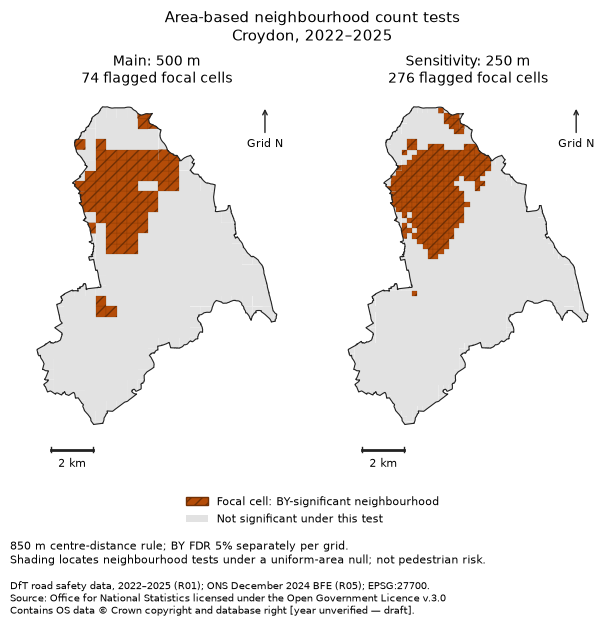

In [9]:
from matplotlib.patches import Patch

def add_report_map_details(ax, bounds, scale_m=2000):
    """Add a grid-north arrow and a metre-based bar below the mapped footprint."""
    xmin, ymin, xmax, ymax = bounds
    width, height = xmax - xmin, ymax - ymin
    ax.set(xlim=(xmin - 0.05 * width, xmax + 0.05 * width),
           ylim=(ymin - 0.14 * height, ymax + 0.05 * height), aspect="equal")
    ax.set_axis_off()
    start_x, bar_y = xmin + 0.06 * width, ymin - 0.08 * height
    ax.plot([start_x, start_x + scale_m], [bar_y, bar_y], color="#222222", linewidth=2)
    for end_x in (start_x, start_x + scale_m):
        ax.plot([end_x, end_x], [bar_y - 0.008 * height, bar_y + 0.008 * height],
                color="#222222", linewidth=1)
    ax.text(start_x + scale_m / 2, bar_y - 0.025 * height, f"{scale_m / 1000:g} km",
            ha="center", va="top", fontsize=8)
    ax.annotate("Grid N", xy=(0.91, 0.96), xytext=(0.91, 0.86),
                xycoords="axes fraction", ha="center", va="center", fontsize=8,
                arrowprops={"arrowstyle": "->", "color": "#222222"})


def add_report_sources(figure):
    """Keep sources and the unresolved product-specific copyright year visible."""
    figure.text(0.02, 0.015,
        "DfT road safety data, 2022–2025 (R01); ONS December 2024 BFE (R05); EPSG:27700.\n"
        "Source: Office for National Statistics licensed under the Open Government Licence v.3.0\n"
        "Contains OS data © Crown copyright and database right [year unverified — draft].",
        ha="left", va="bottom", fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(6.3, 6.3))
fig.subplots_adjust(left=0.02, right=0.98, top=0.85, bottom=0.25, wspace=0.06)
for ax, result, size, label in zip(
        axes, (main_result, sensitivity_result), GRID_SIZES_M, ("Main", "Sensitivity"), strict=True):
    result.plot(ax=ax, color="#e2e2e2", edgecolor="none")
    flagged = result.loc[result["by_significant"]]
    if not flagged.empty:
        flagged.plot(ax=ax, color="#b44c08", edgecolor="#703005", hatch="///", linewidth=0.15)
    footprint_frame.boundary.plot(ax=ax, color="#222222", linewidth=0.8)
    add_report_map_details(ax, footprint.bounds)
    ax.set_title(f"{label}: {size} m\n{len(flagged)} flagged focal cells", fontsize=10)
fig.legend(handles=[Patch(facecolor="#b44c08", edgecolor="#703005", hatch="///",
                         label="Focal cell: BY-significant neighbourhood"),
                    Patch(facecolor="#e2e2e2", label="Not significant under this test")],
           loc="lower center", bbox_to_anchor=(0.5, 0.145), fontsize=8, frameon=False)
fig.suptitle("Area-based neighbourhood count tests\nCroydon, 2022–2025", fontsize=11)
fig.text(0.02, 0.10, "850 m centre-distance rule; BY FDR 5% separately per grid.\n"
         "Shading locates neighbourhood tests under a uniform-area null; not pedestrian risk.", fontsize=8)
add_report_sources(fig)
save_report_figure(fig, "croydon_inference_500m_250m_report.png")
plt.show()


**Findings:** both maps show a broadly consistent northern concentration, with differences in smaller patches. The southern outlying patch is more extensive at 500 m; non-significance does not establish safety.

### 5.9 Limitations

Uniform land area does not model roads, junctions, pedestrian exposure, reporting differences or event dependence. Results describe departures from this baseline, not risk or causality; BY cannot repair invalid model assumptions.

Edge windows exclude events outside the fixed footprint, which is not claimed to equal every year's historical boundary. Grid sensitivity also changes window geometry, test locations and multiplicity; more significant cells do not establish a better grid.

Reporting comparability, coordinate-representation agreement, product-specific map attribution and teaching alignment remain unresolved. The linked exercise teaches Moran methods rather than this custom test, whose acceptance needs confirmation: [R12](../docs/references.md#r12).